/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/seaborn/utils.py:80: UserWarning: Glyph 34920 (\N{CJK UNIFIED IDEOGRAPH-8868}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/seaborn/utils.py:80: UserWarning: Glyph 26684 (\N{CJK UNIFIED IDEOGRAPH-683C}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/seaborn/utils.py:80: UserWarning: Glyph 33539 (\N{CJK UNIFIED IDEOGRAPH-8303}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/home/chendawww/Software/anaconda3/envs/pycbc/lib/python3.12/site-packages/seaborn/utils.py:80: UserWarning: Glyph 22260 (\N{CJK UNIFIED IDEOGRAPH-56F4}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/tmp/ipykernel_24620/1396438850.py:134: UserWarning: Glyph 34920 (\N{CJK UNIFIED IDEOGRAPH-8868}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_

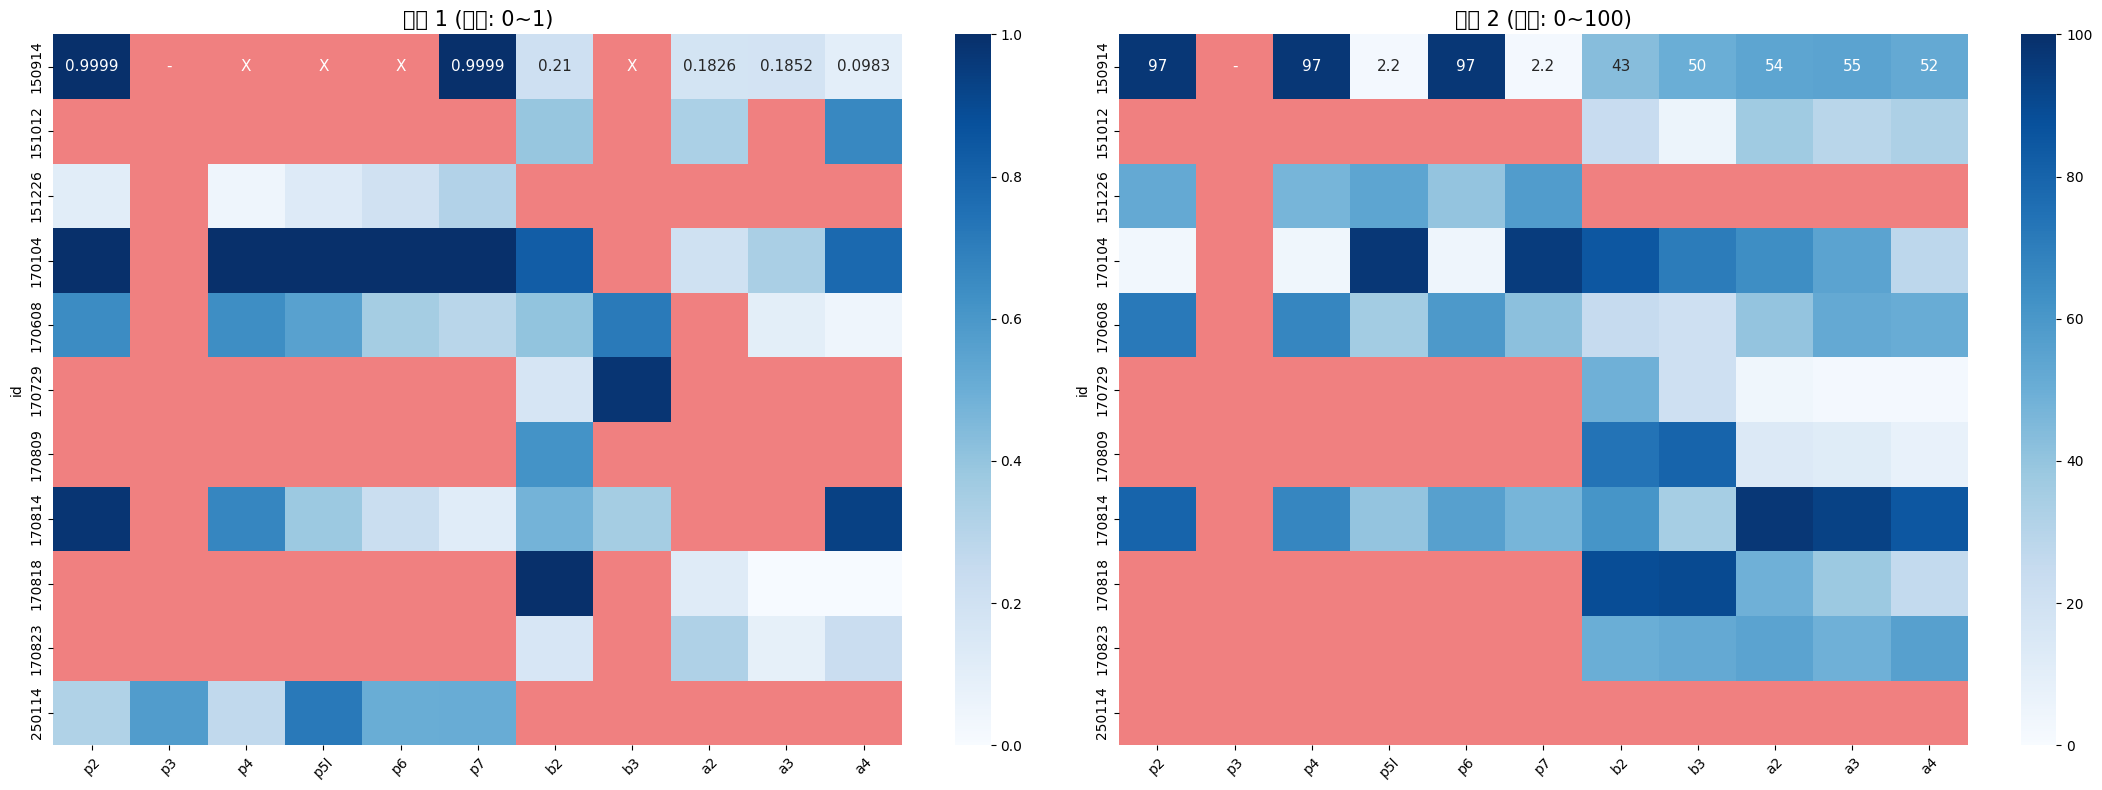

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.cm as cm

# ----------------------
# 1. 数据 (修正语法后)
# ----------------------
data1 = [
    [150914, 0.9999, '-', 'X', 'X', 'X', 0.9999, 0.21, 'X', 0.1826, 0.1852, 0.0983],
    [151012, '/', '/', '/', '/', '/', '/', 0.3931, 'X', 0.3327, 'X', 0.6623],
    [151226, 0.1111, '-', 0.0469, 0.1302, 0.2020, 0.3159, '/', '/', '/', '/', '/'],
    [170104, 0.9999, '-', 0.9999, 0.9999, 0.9999, 0.9999, 0.8265, 'X', 0.2066, 0.3379, 0.7810],
    [170608, 0.6452, '-', 0.6369, 0.5550, 0.3552, 0.2927, 0.4034, 0.7158, 'X', 0.1033, 0.05],
    [170729, '/', '/', '/', '/', '/', '/', 0.1702, 0.9786, 'X', 'X', 'X'],
    [170809, '/', '/', '/', '/', '/', '/', 0.6189, 'X', 'X', 'X', 'X'],
    [170814, 0.98, '-', 0.6714, 0.3817, 0.2291, 0.1135, 0.4800, 0.3536, 'X', 'X', 0.9355],
    [170818, '/', '/', '/', '/', '/', '/', 0.9989, 'X', 0.1236, 0.007, 0.007],
    [170823, '/', '/', '/', '/', '/', '/', 0.1614, 'X', 0.3221, 0.0895, 0.2328],
    [250114, 0.3191, 0.5819, 0.2694, 0.7224, 0.5070, 0.5082, '/', '/', '/', '/', '/']
]
columns1 = ['id', 'p2', 'p3', 'p4', 'p5l', 'p6', 'p7', 'b2', 'b3', 'a2', 'a3', 'a4']
df1 = pd.DataFrame(data1, columns=columns1)

data2 = [
    [150914, 97, '-', 97, 2.2, 97, 2.2, 43, 50, 54, 55, 52],
    [151012, '/', '/', '/', '/', '/', '/', 24, 5.6, 37, 29, 33],
    [151226, 52, '-', 47, 54, 40, 58, '/', '/', '/', '/', '/'],
    [170104, 3.5, '-', 4.2, 97, 4.7, 95, 85, 71, 64, 55, 28],
    [170608, 72, '-', 67, 36, 59, 42, 25, 21, 40, 52, 51],
    [170729, '/', '/', '/', '/', '/', '/', 49, 21, 4, 2.1, 2.2],
    [170809, '/', '/', '/', '/', '/', '/', 74, 80, 14, 12, 7.6],
    [170814, 80, '-', 67, 40, 56, 47, 61, 35, 97, 93, 85],
    [170818, '/', '/', '/', '/', '/', '/', 89, 90, 49, 38, 26],
    [170823, '/', '/', '/', '/', '/', '/', 50, 52, 55, 49, 56],
    [250114, '/', '/', '/', '/', '/', '/', '/', '/', '/', '/', '/']
]
columns2 = ['id', 'p2', 'p3', 'p4', 'p5l', 'p6', 'p7', 'b2', 'b3', 'a2', 'a3', 'a4']
df2 = pd.DataFrame(data2, columns=columns2)

# ----------------------
# 2. 数据清洗函数 (增加强制类型转换)
# ----------------------

def preprocess_data(df):
    # 复制两套：一套用于显示文本（保留特殊字符），一套用于数值计算
    annot_df = df.copy()
    numeric_df = df.copy()

    # 将 ID 设为索引
    id_col = df.columns[0]
    numeric_df = numeric_df.set_index(id_col)
    annot_df = annot_df.set_index(id_col)

    # 循环处理每一列
    for col in numeric_df.columns:
        for idx in numeric_df.index:
            val = numeric_df.loc[idx, col]
            val_str = str(val).strip()

            # 更新显示用的 DataFrame (保留原样，包含 ~ + - X / 等)
            annot_df.loc[idx, col] = val_str

            # 更新数值计算用的 DataFrame
            # 如果包含波浪号 ~，直接设为 NaN，避免热力图颜色映射出错
            if '~' in val_str:
                numeric_df.loc[idx, col] = np.nan
                continue

            # 清理 + 和 - 号
            clean_val = val_str.replace('+', '').replace('-', '')

            # 处理特殊字符 X 和 / -> NaN
            if clean_val.upper() == 'X' or clean_val == '/':
                numeric_df.loc[idx, col] = np.nan
            else:
                try:
                    numeric_df.loc[idx, col] = float(clean_val)
                except ValueError:
                    # 如果清理后仍然无法转为数字，设为 NaN
                    numeric_df.loc[idx, col] = np.nan

    # 关键修复步骤：
    # 强制将所有列转换为数值类型，无法转换的变为 NaN。
    # 这会确保 seaborn heatmap 不再报 "Image data of dtype object" 错误。
    numeric_df = numeric_df.apply(pd.to_numeric, errors='coerce')

    return numeric_df, annot_df

# ----------------------
# 3. 执行绘图
# ----------------------

numeric_df1, annot_df1 = preprocess_data(df1)
numeric_df2, annot_df2 = preprocess_data(df2)

# ----------------------
# 3. 绘制热力图 (白色到蓝色，非数字区域淡红色)
# ----------------------
# 创建白到蓝的色谱副本，并将 NaN 对应的颜色设为淡红色
cmap1 = cm.Blues.copy()
cmap1.set_bad('lightcoral')  # 淡红色

cmap2 = cm.Blues.copy()
cmap2.set_bad('lightcoral')  # 淡红色

fig, axes = plt.subplots(1, 2, figsize=(22, 8))

# 图1 (0~1)
sns.heatmap(numeric_df1, 
            annot=annot_df1, 
            fmt='', 
            cbar=True, 
            cmap=cmap1,           # 使用自定义色谱
            ax=axes[0],
            vmin=0, vmax=1,
            annot_kws={'size': 11})
axes[0].set_title('表格 1 (范围: 0~1)', fontsize=15)
axes[0].tick_params(axis='x', rotation=45)

# 图2 (0~100)
sns.heatmap(numeric_df2, 
            annot=annot_df2, 
            fmt='', 
            cbar=True, 
            cmap=cmap2,           # 使用自定义色谱
            ax=axes[1],
            vmin=0, vmax=100,
            annot_kws={'size': 11})
axes[1].set_title('表格 2 (范围: 0~100)', fontsize=15)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()